In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

In [50]:
# Load dataset
df = pd.read_csv("../data/raw/garment_productivity.csv")

print("Dataset shape:", df.shape)
display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (1197, 15)


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   object 
 1   quarter                1197 non-null   object 
 2   department             1197 non-null   object 
 3   day                    1197 non-null   object 
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-nu

In [51]:
# Convert date column
df["date"] = pd.to_datetime(
    df["date"],
    format="%m/%d/%Y"
)

# Extract date-related features
df["month"] = df["date"].dt.month
df["day_of_month"] = df["date"].dt.day

# Preserve original dates for chronological splitting
dates = df["date"].copy()

# Drop original date column
df = df.drop(columns=["date"])

print("Updated dataset shape:", df.shape)

Updated dataset shape: (1197, 16)


In [52]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
quarter                    0
department                 0
day                        0
team                       0
targeted_productivity      0
smv                        0
wip                      506
over_time                  0
incentive                  0
idle_time                  0
idle_men                   0
no_of_style_change         0
no_of_workers              0
actual_productivity        0
month                      0
day_of_month               0
dtype: int64


In [53]:
# Define target and features
target = "actual_productivity"

X = df.drop(columns=[target, "wip"])
y = df[target]

# Treat team as categorical
X["team"] = X["team"].astype(str)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1197, 14)
Target shape: (1197,)


In [54]:
# Define numerical and categorical features
numerical_features = [
    "targeted_productivity",
    "smv",
    "over_time",
    "incentive",
    "idle_time",
    "idle_men",
    "no_of_style_change",
    "no_of_workers",
    "month",
    "day_of_month"
]

categorical_features = [
    "quarter",
    "department",
    "day",
    "team"
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['targeted_productivity', 'smv', 'over_time', 'incentive', 'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers', 'month', 'day_of_month']

Categorical features:
['quarter', 'department', 'day', 'team']


In [55]:
# Sort unique dates
unique_dates = np.sort(dates.unique())

# Use approximately 80% of dates for training
split_index = int(len(unique_dates) * 0.8)

cutoff_date = unique_dates[split_index]

# Create masks
train_mask = dates < cutoff_date
test_mask = dates >= cutoff_date

# Split features and target
X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Cutoff date:", cutoff_date)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining date range:")
print(dates.loc[train_mask].min(), "to", dates.loc[train_mask].max())

print("\nTesting date range:")
print(dates.loc[test_mask].min(), "to", dates.loc[test_mask].max())

print("\nTraining target mean:", y_train.mean())
print("Testing target mean:", y_test.mean())

Cutoff date: 2015-02-26T00:00:00.000000000

Training records: 943
Testing records: 254

Training date range:
2015-01-01 00:00:00 to 2015-02-25 00:00:00

Testing date range:
2015-02-26 00:00:00 to 2015-03-11 00:00:00

Training target mean: 0.7428822260540828
Testing target mean: 0.7061657634448819


In [56]:
# Create original preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ), categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (943, 31)
Processed testing shape: (254, 31)


In [57]:
# Define baseline models
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

trained_models = {}
predictions = {}

# Train and predict
for name, model in models.items():

    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)

    trained_models[name] = model
    predictions[name] = y_pred

    print(f"{name} trained successfully.")

Linear Regression trained successfully.
Ridge Regression trained successfully.
Random Forest trained successfully.
Gradient Boosting trained successfully.


In [58]:
# Evaluate baseline models
results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

baseline_results = pd.DataFrame(results)

baseline_results = baseline_results.sort_values(
    by="RMSE"
)

display(baseline_results)

,Model,MAE,RMSE,R2 Score
2,Random Forest,0.091832,0.133044,0.323863
3,Gradient Boosting,0.096488,0.141281,0.237551
1,Ridge Regression,0.287749,1.138884,-48.545341
0,Linear Regression,0.288825,1.143932,-48.985538


In [59]:
# Random Forest feature importance
rf_model = trained_models["Random Forest"]

feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
0,num__targeted_productivity,0.231420
3,num__incentive,0.145950
1,num__smv,0.130334
9,num__day_of_month,0.101486
7,num__no_of_workers,0.076755
2,num__over_time,0.072106
16,cat__day_Sunday,0.018344
19,cat__day_Wednesday,0.017045
21,cat__team_11,0.015701
10,cat__quarter_Quarter2,0.014270


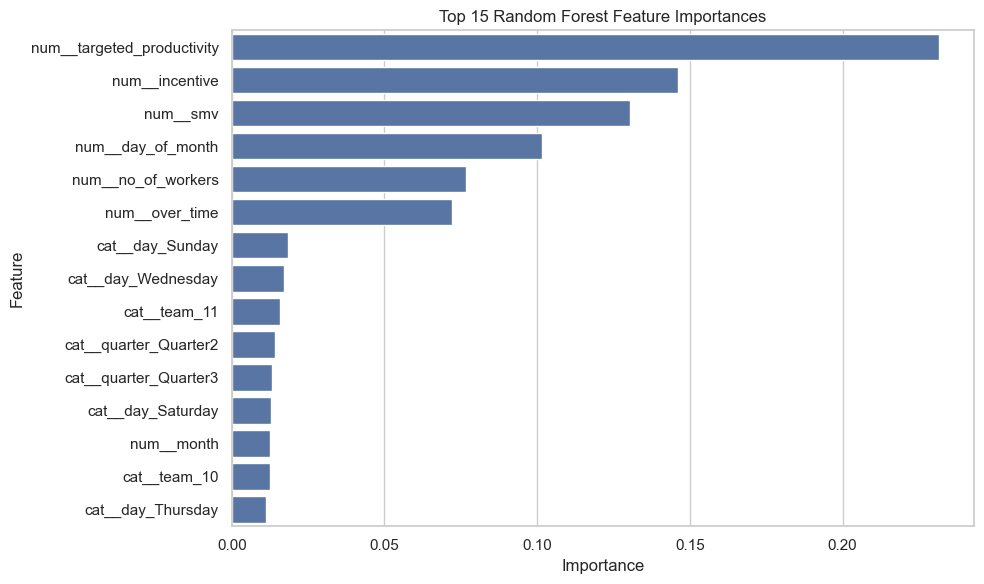

In [60]:
# Visualize top 15 important features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [69]:
preprocessor_cv = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),

        ("cat", OneHotEncoder(
            handle_unknown="ignore"
        ), categorical_features)
    ]
)

In [70]:
pipeline = Pipeline([
    ("preprocessor", preprocessor_cv),

    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

print("Pipeline created successfully.")

Pipeline created successfully.


In [71]:
# Get dates corresponding to training records
train_dates = dates.loc[X_train.index].reset_index(drop=True)

# Get sorted unique training dates
unique_train_dates = np.sort(train_dates.unique())

print("Number of unique training dates:", len(unique_train_dates))

# Create expanding-window splits
tscv = TimeSeriesSplit(n_splits=5)

date_splits = []

for train_date_idx, val_date_idx in tscv.split(unique_train_dates):

    train_fold_dates = unique_train_dates[train_date_idx]
    val_fold_dates = unique_train_dates[val_date_idx]

    # Convert date indices into row indices
    train_row_idx = np.flatnonzero(
        train_dates.isin(train_fold_dates).to_numpy()
    )

    val_row_idx = np.flatnonzero(
        train_dates.isin(val_fold_dates).to_numpy()
    )

    date_splits.append((train_row_idx, val_row_idx))


# Display fold information
print("\nCross-validation fold details:")

for i, (train_idx, val_idx) in enumerate(date_splits, start=1):

    print(f"\nFold {i}")

    print("Training records:", len(train_idx))
    print("Validation records:", len(val_idx))

    print(
        "Training dates:",
        train_dates.iloc[train_idx].min(),
        "to",
        train_dates.iloc[train_idx].max()
    )

    print(
        "Validation dates:",
        train_dates.iloc[val_idx].min(),
        "to",
        train_dates.iloc[val_idx].max()
    )

Number of unique training dates: 47

Cross-validation fold details:

Fold 1
Training records: 259
Validation records: 134
Training dates: 2015-01-01 00:00:00 to 2015-01-14 00:00:00
Validation dates: 2015-01-15 00:00:00 to 2015-01-22 00:00:00

Fold 2
Training records: 393
Validation records: 149
Training dates: 2015-01-01 00:00:00 to 2015-01-22 00:00:00
Validation dates: 2015-01-24 00:00:00 to 2015-01-31 00:00:00

Fold 3
Training records: 542
Validation records: 132
Training dates: 2015-01-01 00:00:00 to 2015-01-31 00:00:00
Validation dates: 2015-02-01 00:00:00 to 2015-02-08 00:00:00

Fold 4
Training records: 674
Validation records: 129
Training dates: 2015-01-01 00:00:00 to 2015-02-08 00:00:00
Validation dates: 2015-02-09 00:00:00 to 2015-02-16 00:00:00

Fold 5
Training records: 803
Validation records: 140
Training dates: 2015-01-01 00:00:00 to 2015-02-16 00:00:00
Validation dates: 2015-02-17 00:00:00 to 2015-02-25 00:00:00


In [72]:
# Define hyperparameter search space
param_dist = {
    "model__n_estimators": [100, 200, 300, 500],

    "model__max_depth": [None, 5, 10, 15, 20],

    "model__min_samples_split": [2, 5, 10],

    "model__min_samples_leaf": [1, 2, 4],

    "model__max_features": ["sqrt", 0.7, 1.0]
}

In [73]:
# Initialize RandomizedSearchCV
random_search_cv = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=30,
    cv=date_splits,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Run hyperparameter tuning
random_search_cv.fit(X_train, y_train)

print("Best Parameters:")
print(random_search_cv.best_params_)

print("\nBest Cross-validation RMSE:")
print(-random_search_cv.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 0.7, 'model__max_depth': 20}

Best Cross-validation RMSE:
0.1473120271140426


In [75]:
# Retrieve best pipeline
best_model = random_search_cv.best_estimator_

# Generate predictions
y_pred_tuned = best_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred_tuned)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_tuned)
)

r2 = r2_score(y_test, y_pred_tuned)

print("Leakage-Safe Tuned Random Forest Results")
print("----------------------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Leakage-Safe Tuned Random Forest Results
----------------------------------------
MAE: 0.08932270980743925
RMSE: 0.13220719825339303
R2 Score: 0.33234174634808555


In [77]:
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],

    "Previous Tuned RF": [
        0.0894142597,
        0.1329904730,
        0.3244070946
    ],

    "Leakage-Safe Tuned RF": [
        mae,
        rmse,
        r2
    ]
})

display(comparison)

,Metric,Previous Tuned RF,Leakage-Safe Tuned RF
0,MAE,0.089414,0.089323
1,RMSE,0.132990,0.132207
2,R2 Score,0.324407,0.332342


In [78]:
baseline_rf = baseline_results[
    baseline_results["Model"] == "Random Forest"
].iloc[0]

model_comparison = pd.DataFrame({
    "Model": [
        "Baseline Random Forest",
        "Previous Tuned Random Forest",
        "Leakage-Safe Tuned Random Forest"
    ],

    "MAE": [
        baseline_rf["MAE"],
        0.0894142597,
        mae
    ],

    "RMSE": [
        baseline_rf["RMSE"],
        0.1329904730,
        rmse
    ],

    "R2 Score": [
        baseline_rf["R2 Score"],
        0.3244070946,
        r2
    ]
})

display(model_comparison)

,Model,MAE,RMSE,R2 Score
0,Baseline Random Forest,0.091832,0.133044,0.323863
1,Previous Tuned Random Forest,0.089414,0.132990,0.324407
2,Leakage-Safe Tuned Random Forest,0.089323,0.132207,0.332342


In [84]:
best_params = random_search_cv.best_params_

print(best_params)

{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 0.7, 'model__max_depth': 20}


In [85]:
numerical_features_no_target = [
    col for col in numerical_features
    if col != "targeted_productivity"
]

preprocessor_no_target = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features_no_target),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [86]:
rf_no_target = Pipeline([
    ("preprocessor", preprocessor_no_target),
    ("model", RandomForestRegressor(
        n_estimators=best_params["model__n_estimators"],
        min_samples_split=best_params["model__min_samples_split"],
        min_samples_leaf=best_params["model__min_samples_leaf"],
        max_features=best_params["model__max_features"],
        max_depth=best_params["model__max_depth"],
        random_state=42,
        n_jobs=-1
    ))
])

rf_no_target.fit(X_train, y_train)

y_pred_no_target = rf_no_target.predict(X_test)

In [87]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_no_target = mean_absolute_error(y_test, y_pred_no_target)
rmse_no_target = np.sqrt(mean_squared_error(y_test, y_pred_no_target))
r2_no_target = r2_score(y_test, y_pred_no_target)

print("Random Forest Without Targeted Productivity")
print("MAE:", mae_no_target)
print("RMSE:", rmse_no_target)
print("R2 Score:", r2_no_target)

Random Forest Without Targeted Productivity
MAE: 0.10453179907140231
RMSE: 0.14926705137443932
R2 Score: 0.14891697917232805


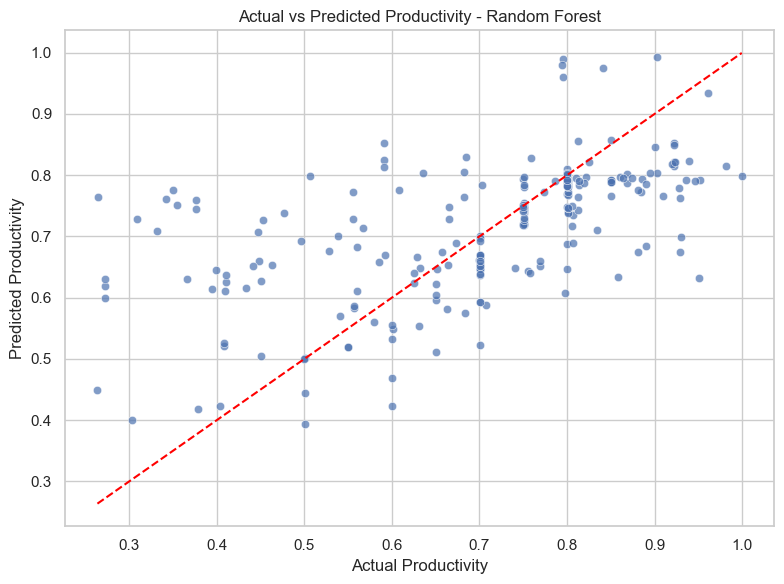

In [88]:
import matplotlib.pyplot as plt
import seaborn as sns

# Actual vs Predicted Productivity
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_tuned,
    alpha=0.7
)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color="red"
)

plt.xlabel("Actual Productivity")
plt.ylabel("Predicted Productivity")
plt.title("Actual vs Predicted Productivity - Random Forest")

plt.tight_layout()
plt.show()

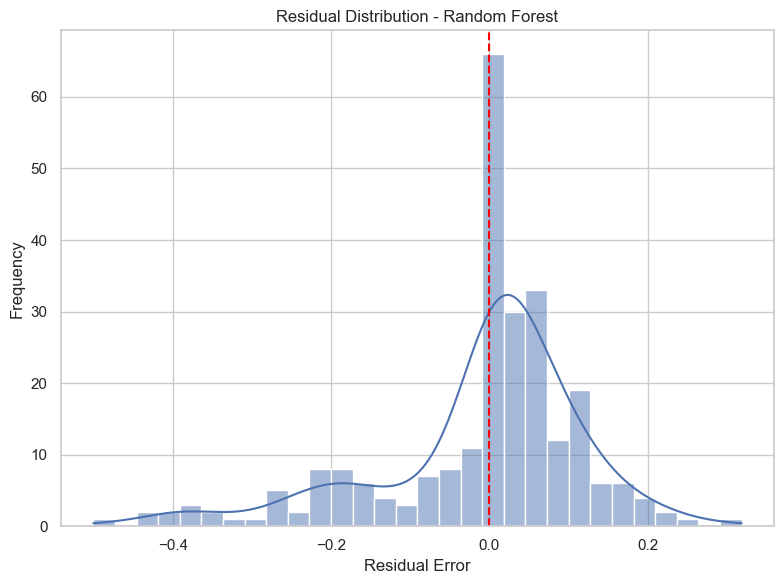

In [89]:
# Calculate residuals
residuals = y_test - y_pred_tuned

# Plot residual distribution
plt.figure(figsize=(8, 6))

sns.histplot(
    residuals,
    kde=True,
    bins=30
)

plt.axvline(0, linestyle="--", color="red")

plt.xlabel("Residual Error")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Random Forest")

plt.tight_layout()
plt.show()

In [90]:
# Create evaluation dataframe
evaluation_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_tuned,
    "Residual": y_test - y_pred_tuned,
    "Department": X_test["department"]
})

# Calculate department-level performance
department_performance = evaluation_df.groupby("Department").apply(
    lambda group: pd.Series({
        "MAE": mean_absolute_error(group["Actual"], group["Predicted"]),
        "RMSE": np.sqrt(mean_squared_error(group["Actual"], group["Predicted"])),
        "Mean Residual": group["Residual"].mean(),
        "Records": len(group)
    }),
    include_groups=False
)

department_performance

,MAE,RMSE,Mean Residual,Records
Department,,,,
finishing,0.144585,0.180094,-0.042378,115.0
sweing,0.043602,0.071455,0.016497,139.0


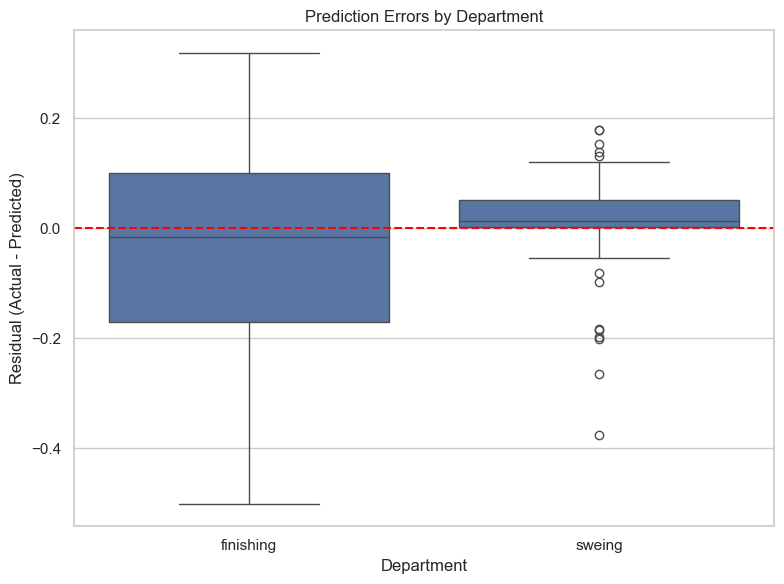

In [91]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=evaluation_df,
    x="Department",
    y="Residual"
)

plt.axhline(0, linestyle="--", color="red")

plt.title("Prediction Errors by Department")
plt.xlabel("Department")
plt.ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

In [92]:
evaluation_df["Date"] = pd.to_datetime(
    pd.read_csv("../data/raw/garment_productivity.csv")["date"],
    format="%m/%d/%Y"
).loc[y_test.index].values

daily_performance = evaluation_df.groupby("Date").apply(
    lambda group: pd.Series({
        "MAE": mean_absolute_error(group["Actual"], group["Predicted"]),
        "RMSE": np.sqrt(mean_squared_error(group["Actual"], group["Predicted"])),
        "Records": len(group)
    })
)

daily_performance.head(10)

,MAE,RMSE,Records
Date,,,
2015-02-26,0.107594,0.152754,21.0
2015-02-28,0.098494,0.148575,21.0
2015-03-01,0.089309,0.136673,20.0
2015-03-02,0.078121,0.130161,20.0
2015-03-03,0.110696,0.160907,22.0
2015-03-04,0.084871,0.123917,21.0
2015-03-05,0.097147,0.138920,19.0
2015-03-07,0.076771,0.103305,19.0
2015-03-08,0.111765,0.141142,22.0


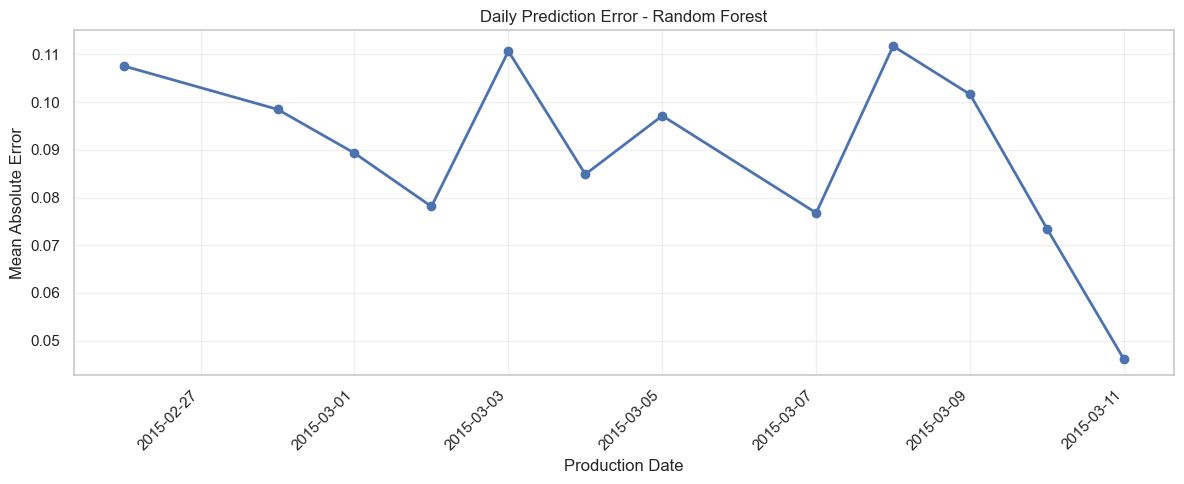

In [93]:
plt.figure(figsize=(12, 5))

daily_performance["MAE"].plot(
    marker="o",
    linewidth=2
)

plt.title("Daily Prediction Error - Random Forest")
plt.xlabel("Production Date")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()